# Лабораторная работа №1: регрессия (Wine Quality)

**Задача:** предсказать оценку качества вина `quality` (целое число от 0 до 10, выставленное экспертами) по 11 физико-химическим характеристикам.

**Метрики:** основная — RMSE, дополнительная — MAE. Порог: RMSE < 0.70.

План работы:
1. Знакомство с данными (EDA) и выводы.
2. Разбиение на train / test.
3. Baseline — константное предсказание.
4. Модели: линейная регрессия, Random Forest, Gradient Boosting (+ дополнительно Extra Trees).
5. Честное сравнение, итоговая таблица.
6. Feature importance.
7. Анализ ошибок лучшей модели.

In [1]:
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

%matplotlib inline
sns.set(style="darkgrid")
pd.set_option("display.precision", 3)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Знакомство с данными

Датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) состоит из двух файлов: красные (`winequality-red.csv`, 1599 вин) и белые (`winequality-white.csv`, 4898 вин) вина португальского Vinho Verde. Объединяем их в одну таблицу и добавляем бинарный признак `is_red`: тип вина — важная информация, и одна общая модель обучится на большем объёме данных.

In [2]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0
df = pd.concat([red, white], ignore_index=True)
df.columns = [c.replace(" ", "_") for c in df.columns]

TARGET = "quality"
FEATURES = [c for c in df.columns if c != TARGET]
print("Размер:", df.shape)
df.head()

Размер: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile_acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric_acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual_sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free_sulfur_dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total_sulfur_dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


In [5]:
print("Пропусков всего:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum(), f"({df.duplicated().mean():.1%})")
print("Строк-дубликатов по признакам с разным quality:",
      df.groupby(FEATURES)[TARGET].nunique().gt(1).sum())

Пропусков всего: 0
Полных дубликатов строк: 1177 (18.1%)
Строк-дубликатов по признакам с разным quality: 0


**Выводы по структуре данных:**
* Пропусков нет, все признаки числовые — кодирование категорий и заполнение пропусков не требуются.
* Около 18% строк — полные дубликаты (одинаковые признаки и оценка). Скорее всего, это разные бутылки одной партии или повторные записи. Удалять их мы не будем: скрытая тестовая выборка взята из того же датасета и тоже содержит такие повторы. Но из-за них оценка на тесте может оказаться немного оптимистичной: модель «видела» точную копию тестового объекта. Отдельно проверим это в конце (раздел 5.1).
* Масштабы признаков очень разные: `total_sulfur_dioxide` — десятки и сотни, `density` и `chlorides` — доли единицы. Для линейной модели это значит, что нужно масштабирование (раздел 4.1).

### 1.1 Целевая переменная

quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: proportion, dtype: float64

Средняя оценка: 5.818, std: 0.873
         mean    std  count
is_red                     
0       5.878  0.886   4898
1       5.636  0.808   1599


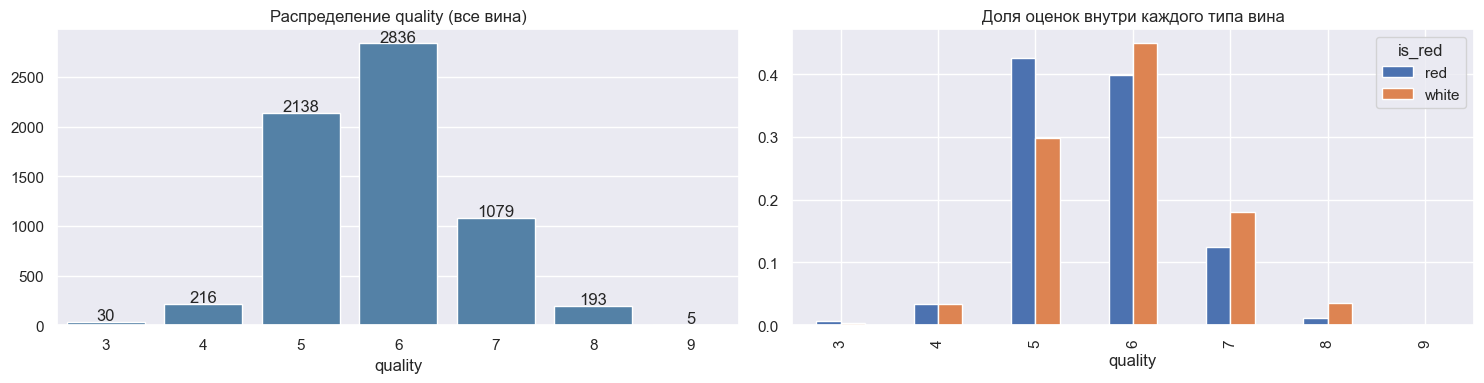

In [6]:
fig, axs = plt.subplots(figsize=(15, 4), ncols=2)
counts = df[TARGET].value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, ax=axs[0], color="steelblue")
axs[0].set_title("Распределение quality (все вина)")
for i, v in enumerate(counts.values):
    axs[0].text(i, v + 20, str(v), ha="center")

ct = pd.crosstab(df[TARGET], df["is_red"].map({0: "white", 1: "red"}), normalize="columns")
ct.plot(kind="bar", ax=axs[1])
axs[1].set_title("Доля оценок внутри каждого типа вина")
plt.tight_layout()

print(df[TARGET].value_counts(normalize=True).sort_index().round(3))
print("\nСредняя оценка: %.3f, std: %.3f" % (df[TARGET].mean(), df[TARGET].std()))
print(df.groupby("is_red")[TARGET].agg(["mean", "std", "count"]))

**Выводы по целевой переменной:**
* Распределение сильно несбалансировано: оценки 5 и 6 составляют ~77% выборки, а 3, 4, 8, 9 вместе — меньше 8% (оценка 9 встречается всего 5 раз, 0–2 и 10 нет совсем). Модель, которая минимизирует квадратичную ошибку, будет «тянуть» прогнозы к центру (5–6), поэтому на крайних оценках ожидаются большие ошибки. Это проверим в анализе ошибок.
* Стандартное отклонение quality ≈ 0.87, значит RMSE константного прогноза будет около 0.87. Порог 0.70 — это снижение ошибки примерно на 20% относительно «ничего не знающей» модели.
* Цель дискретная, но упорядоченная, поэтому её разумно решать как регрессию (так требует задание). Ошибка 5→6 и 5→8 действительно должна штрафоваться по-разному.
* Белые вина в среднем оцениваются чуть выше (5.88 против 5.64), поэтому тип вина стоит оставить как признак.

### 1.2 Распределения признаков

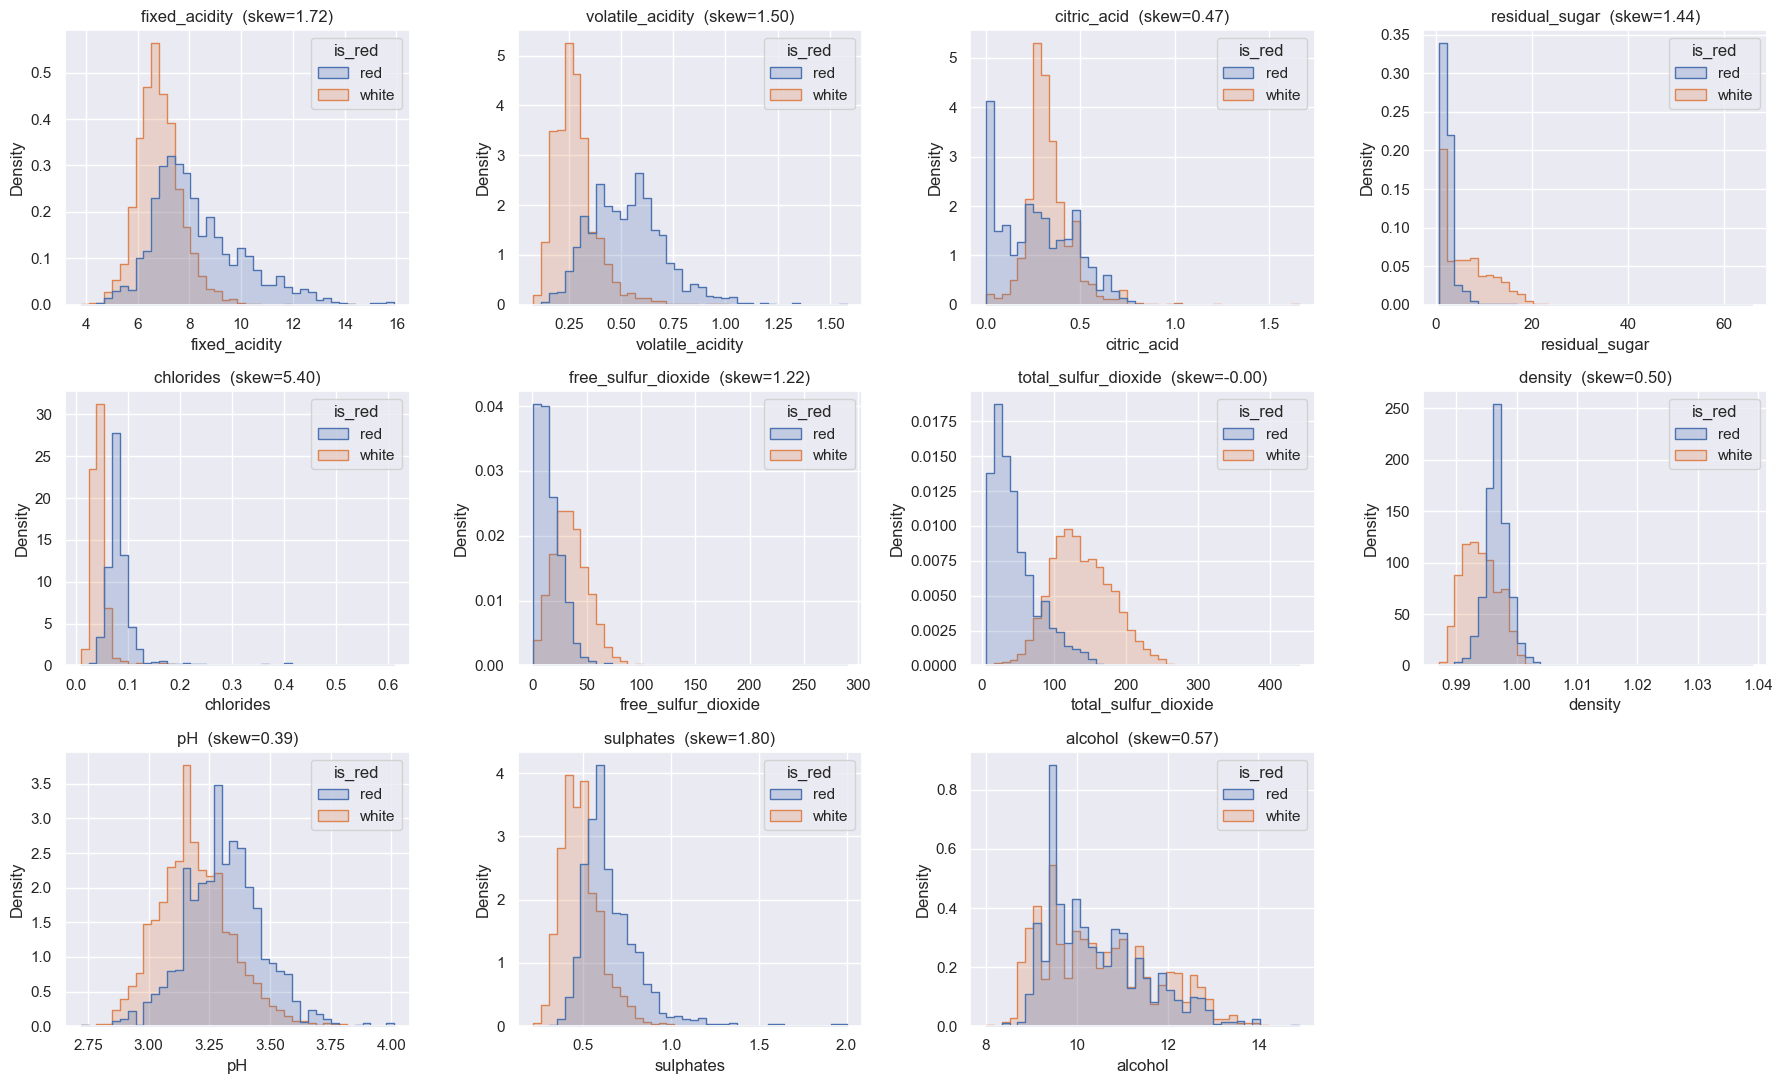

In [7]:
num_features = [f for f in FEATURES if f != "is_red"]
fig, axs = plt.subplots(nrows=3, ncols=4, figsize=(18, 11))
for ax, f in zip(axs.ravel(), num_features):
    sns.histplot(data=df, x=f, hue=df["is_red"].map({0: "white", 1: "red"}), ax=ax,
                 stat="density", common_norm=False, bins=40, element="step")
    ax.set_title(f"{f}  (skew={df[f].skew():.2f})")
axs.ravel()[-1].axis("off")
plt.tight_layout()

**Выводы:**
* Многие признаки скошены вправо и имеют выбросы: `residual_sugar`, `chlorides`, `free/total_sulfur_dioxide`, `sulphates`. Деревьям это не мешает: они инвариантны к монотонным преобразованиям признаков. Линейную модель отдельные экстремальные точки могут заметно сдвигать.
* Красные и белые вина различаются по распределениям очень сильно: у белых больше сахара и диоксида серы, у красных больше `volatile_acidity`, `chlorides`, `sulphates`. По сути это две разные популяции. Связь признаков с качеством внутри них тоже может отличаться, и линейная модель без взаимодействий этого не учтёт.

### 1.3 Связь признаков с качеством

,all,red,white
alcohol,0.447,0.479,0.440
density,-0.323,-0.177,-0.348
chlorides,-0.295,-0.190,-0.314
volatile_acidity,-0.258,-0.381,-0.197
is_red,-0.123,NaN,NaN
citric_acid,0.106,0.213,0.018
fixed_acidity,-0.098,0.114,-0.084
free_sulfur_dioxide,0.087,-0.057,0.024
total_sulfur_dioxide,-0.055,-0.197,-0.197
pH,0.033,-0.044,0.109


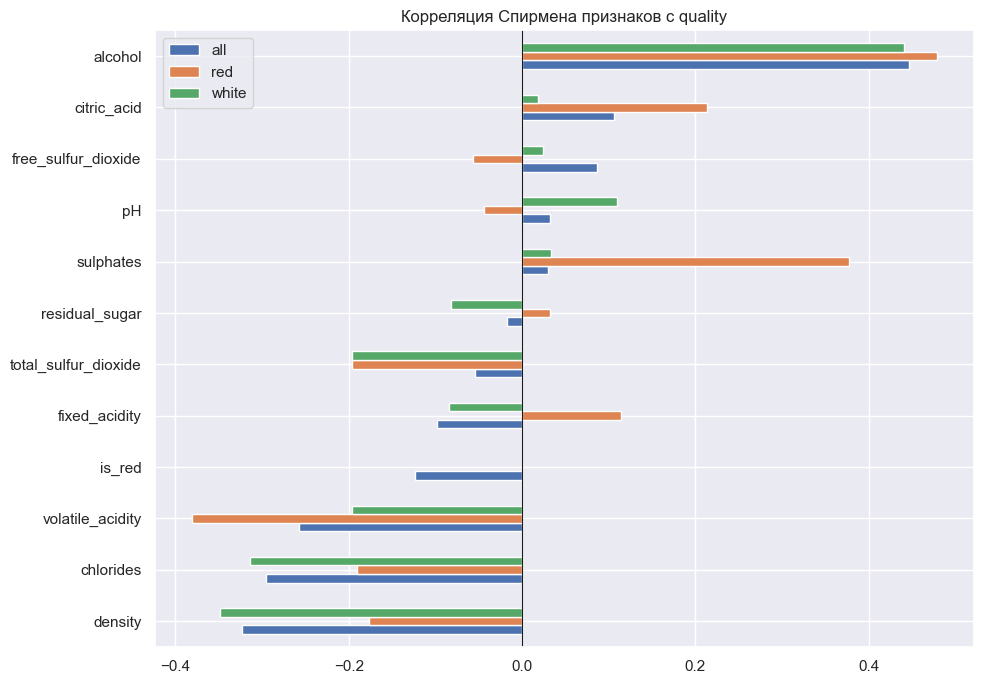

In [8]:
corr_all = df[FEATURES].corrwith(df[TARGET], method="spearman")
corr_red = red.rename(columns=lambda c: c.replace(" ", "_"))[num_features].corrwith(red["quality"], method="spearman")
corr_white = white.rename(columns=lambda c: c.replace(" ", "_"))[num_features].corrwith(white["quality"], method="spearman")
corr_tbl = pd.DataFrame({"all": corr_all, "red": corr_red, "white": corr_white}).sort_values("all")

corr_tbl.plot(kind="barh", figsize=(10, 7))
plt.axvline(0, color="k", lw=0.8)
plt.title("Корреляция Спирмена признаков с quality")
plt.tight_layout()
corr_tbl.sort_values("all", key=abs, ascending=False)

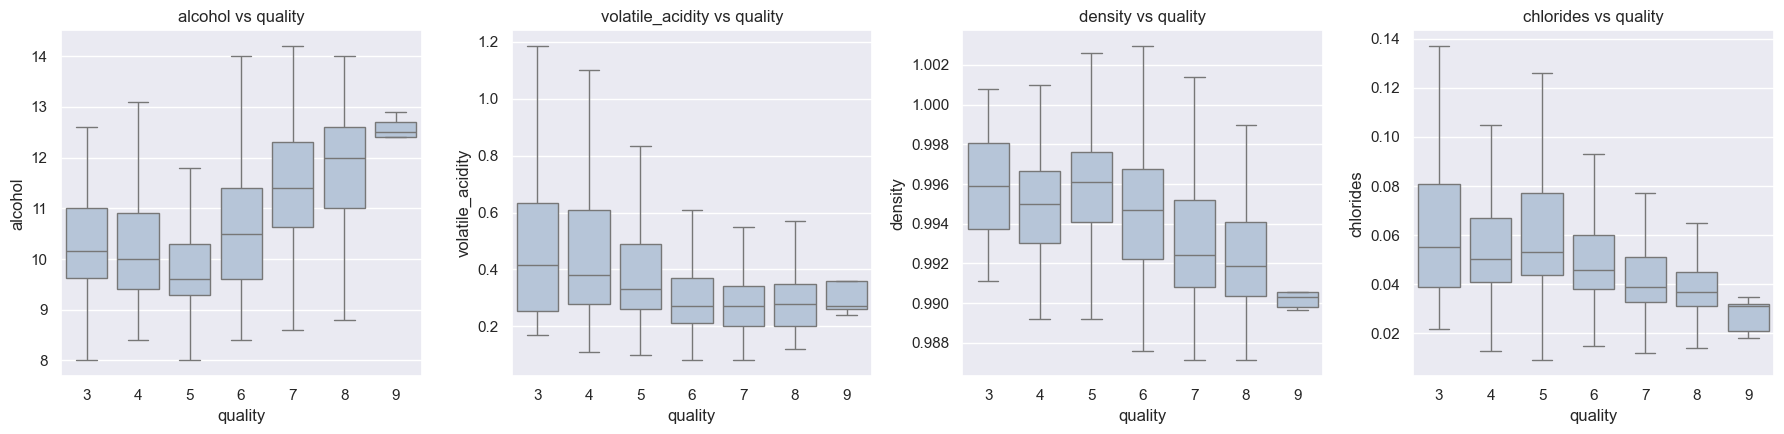

In [9]:
fig, axs = plt.subplots(figsize=(18, 4.5), ncols=4)
for ax, f in zip(axs, ["alcohol", "volatile_acidity", "density", "chlorides"]):
    sns.boxplot(data=df, x=TARGET, y=f, ax=ax, showfliers=False, color="lightsteelblue")
    ax.set_title(f"{f} vs quality")
plt.tight_layout()

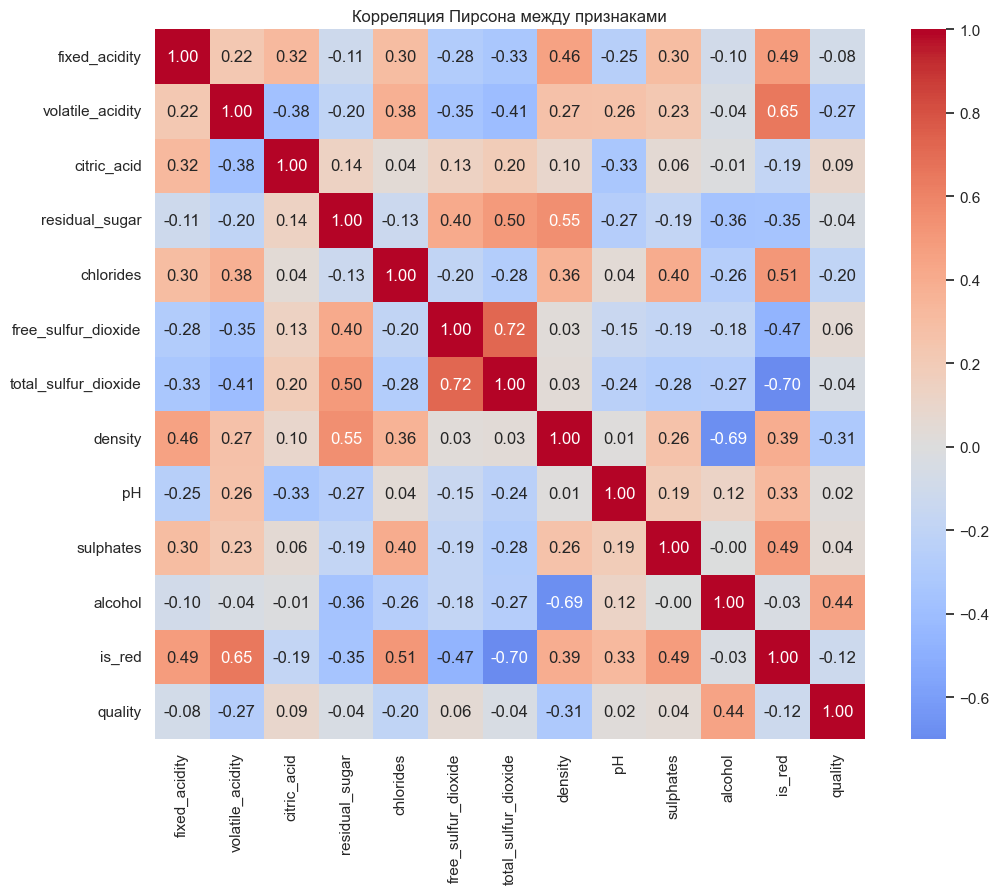

In [10]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Корреляция Пирсона между признаками")
plt.tight_layout()

**Выводы о связи признаков с качеством:**
* **`alcohol`** — самый сильный предиктор (ρ ≈ 0.45). На boxplot медиана содержания алкоголя монотонно растёт от оценки 5 до 9. Содержательно: в более спелом винограде больше сахара, после брожения он даёт более крепкое вино с насыщенным вкусом, и эксперты ставят ему оценки выше. Этот признак обязательно нужно использовать, и в любой модели он, скорее всего, окажется главным.
* **`density`** (ρ ≈ −0.32) коррелирует с quality почти только через алкоголь и сахар: спирт легче воды, поэтому `corr(density, alcohol) ≈ −0.69`. Самостоятельной информации в плотности мало, а в линейной модели такая мультиколлинеарность делает коэффициенты неустойчивыми и плохо интерпретируемыми.
* **`volatile_acidity`** (летучая кислотность, по сути уксусная кислота) — отрицательная связь. Это признак дефекта вина (уксусный привкус), и физический смысл согласуется со знаком. Связь гораздо сильнее у красных вин (ρ ≈ −0.38), чем у белых (ρ ≈ −0.20).
* **`chlorides`** (солёность) отрицательно связана с качеством.
* Некоторые признаки ведут себя **по-разному для красных и белых**: например, `sulphates` и `citric_acid` положительно связаны с качеством у красных и почти никак у белых, а `residual_sugar` у белых связан с качеством отрицательно. Отсюда ожидание, что нелинейные модели с взаимодействиями (деревья) выиграют у одной общей линейной модели.
* Даже лучший признак объясняет лишь малую долю дисперсии (ρ² ≈ 0.2). Оценки субъективны, данные шумные, поэтому снизить ошибку почти до нуля не получится. Реалистичная цель — RMSE в районе 0.6.
* Сильно коррелированы между собой `free_` и `total_sulfur_dioxide` (≈ 0.72), а также оба они с типом вина. Деревьям это не мешает, но важность будет «размазываться» между такими признаками.

## 2. Подготовка выборок

* **Размер:** 80% train (5197 объектов) / 20% test (1300 объектов). Датасет небольшой, поэтому большую часть оставляем для обучения. 1300 тестовых объектов достаточно для стабильной оценки RMSE: стандартная ошибка оценки порядка 0.01–0.02.
* **Способ разбиения:** случайное, **стратифицированное по паре (тип вина, quality)**. Так распределения редких оценок (3, 4, 8, 9) и доля красных/белых совпадают в train и test, иначе на 1300 объектах редкие оценки могли бы почти пропасть из теста или из обучения. Для стратификации оценки 3 и 9 объединены с соседними (`clip(4, 8)`): у класса 9 всего 5 объектов.
* `random_state = 42` фиксирован.
* **Тестовую выборку используем один раз** — для финальной оценки уже выбранных моделей. Гиперпараметры подбираем **кросс-валидацией (5 фолдов) только на train**.

**Почему нельзя многократно оценивать модели на одном и том же тесте?** Если выбирать модель, признаки или гиперпараметры по результату на тесте, тест фактически становится частью обучения: мы подгоняем решение под конкретные 1300 объектов, включая их шум. Оценка становится оптимистично смещённой (переобучение на тест, «утечка» информации). На новых данных, например на скрытой тестовой выборке, качество окажется хуже. Чем больше сравнений на одном тесте, тем сильнее это смещение (multiple comparisons): какая-нибудь модель обязательно окажется «лучшей» случайно.

In [11]:
X = df[FEATURES]
y = df[TARGET]
strata = df["is_red"].astype(str) + "_" + y.clip(4, 8).astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=strata
)
print("train:", X_train.shape, " test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True).sort_index(),
              "test": y_test.value_counts(normalize=True).sort_index()}).T.round(3)

train: (5197, 12)  test: (1300, 12)


quality,3,4,5,6,7,8,9
train,0.005,0.033,0.329,0.436,0.166,0.030,0.001
test,0.004,0.035,0.328,0.437,0.166,0.028,0.002


## 3. Метрики и baseline

$$\text{MAE} = \frac1\ell\sum|y_i - a(x_i)|, \qquad \text{RMSE} = \sqrt{\frac1\ell\sum (y_i - a(x_i))^2}$$

* **MAE** — средняя абсолютная ошибка в единицах целевой переменной: «в среднем модель ошибается на столько баллов». Все ошибки весят пропорционально своему размеру.
* **RMSE** — корень из средней квадратичной ошибки, тоже в баллах. Ошибки сначала возводятся в квадрат, поэтому RMSE показывает, насколько велики ошибки «с учётом крупных промахов».
* **Почему RMSE сильнее реагирует на большие ошибки:** из-за квадрата. Ошибка в 2 балла вносит в сумму 4, а четыре ошибки по 0.5 вместе дают лишь 1. Одна большая ошибка весит как много мелких.
* **Почему MAE и RMSE могут заметно различаться:** всегда RMSE ≥ MAE, равенство достигается, только когда все ошибки одинаковы по модулю. Чем «тяжелее хвост» распределения ошибок (несколько крупных промахов при множестве мелких), тем больше разрыв. Отношение RMSE/MAE — индикатор крупных ошибок: для нормального распределения ошибок оно ≈ 1.25.

**Выбор константы для baseline.** Константа, которая минимизирует MSE (а значит и RMSE), — **среднее** $\bar y$ обучающей выборки. Константа, оптимальная для MAE, — **медиана**. Основная метрика здесь RMSE, поэтому baseline — среднее по train. Медиану покажем для справки. Константу считаем **по train**, а качество — на test.

In [12]:
results = {}

def evaluate(name, y_true, y_pred):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae}
    print(f"{name:25s} RMSE = {rmse:.4f}   MAE = {mae:.4f}")

const_mean = y_train.mean()
const_median = y_train.median()
print(f"mean(y_train) = {const_mean:.4f}, median(y_train) = {const_median}")

evaluate("Baseline (mean)", y_test, np.full(len(y_test), const_mean))
mae_med = mean_absolute_error(y_test, np.full(len(y_test), const_median))
rmse_med = root_mean_squared_error(y_test, np.full(len(y_test), const_median))
print(f"{'(справка) const = median':25s} RMSE = {rmse_med:.4f}   MAE = {mae_med:.4f}")

mean(y_train) = 5.8184, median(y_train) = 6.0
Baseline (mean)           RMSE = 0.8732   MAE = 0.6853
(справка) const = median  RMSE = 0.8918   MAE = 0.6369


Baseline даёт RMSE ≈ 0.87 (практически std целевой переменной, как и должно быть). Медиана (6) даёт меньший MAE, но больший RMSE: каждая константа оптимальна для «своей» метрики. Любая полезная модель должна быть заметно лучше 0.87.

## 4. Модели

Все модели оцениваются одинаково: 5-fold CV на train (одни и те же фолды) для выбора параметров, затем одно финальное измерение на test.

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(model, X_=X_train, y_=y_train):
    scores = -cross_val_score(model, X_, y_, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return scores.mean(), scores.std()

### 4.1 Линейная регрессия

**Нужно ли масштабирование?** Для качества обычной `LinearRegression` (МНК без регуляризации) — нет: решение эквивариантно к линейному масштабированию признаков, прогнозы получаются те же, коэффициенты просто пересчитываются. Но для **интерпретации** масштабирование необходимо: коэффициент — это изменение прогноза при изменении признака на 1 единицу его шкалы. Единица `density` (г/см³) — это почти весь диапазон плотности, единица `total_sulfur_dioxide` (мг/л) — ничтожная величина. Сравнивать такие коэффициенты бессмысленно. После `StandardScaler` коэффициент означает изменение прогноза quality **при изменении признака на одно стандартное отклонение** при прочих фиксированных, и коэффициенты становятся сравнимыми. Для моделей с регуляризацией (Ridge) масштабирование влияет уже и на качество: штраф одинаково давит на все веса.

In [14]:
lr_raw = LinearRegression()
lr = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])

print("CV RMSE LinearRegression (без масштаба): %.4f ± %.4f" % cv_rmse(lr_raw))
print("CV RMSE LinearRegression (StandardScaler): %.4f ± %.4f" % cv_rmse(lr))

ridge_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
    {"model__alpha": np.logspace(-3, 3, 25)}, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_search.fit(X_train, y_train)
print("Ridge: best alpha = %.3f, CV RMSE = %.4f" % (ridge_search.best_params_["model__alpha"], -ridge_search.best_score_))

CV RMSE LinearRegression (без масштаба): 0.7353 ± 0.0245


CV RMSE LinearRegression (StandardScaler): 0.7353 ± 0.0245


Ridge: best alpha = 10.000, CV RMSE = 0.7353


Масштабирование, как и ожидалось, не изменило качество `LinearRegression`. Регуляризация (Ridge) тоже почти ничего не даёт: объектов (~5200) много больше, чем признаков (12), и модель не переобучается. Ей скорее не хватает гибкости (это **недообучение / high bias**). Итоговая линейная модель — `StandardScaler + LinearRegression`.

In [15]:
lr.fit(X_train, y_train)
evaluate("Linear Regression", y_test, lr.predict(X_test))
print("Train RMSE: %.4f" % root_mean_squared_error(y_train, lr.predict(X_train)))

Linear Regression         RMSE = 0.7320   MAE = 0.5670
Train RMSE: 0.7326


,coef_raw,feature_std,coef_scaled
density,-100.865,0.003,-0.303
residual_sugar,0.061,4.794,0.293
alcohol,0.223,1.191,0.266
volatile_acidity,-1.514,0.164,-0.248
is_red,0.393,0.431,0.169
fixed_acidity,0.082,1.289,0.106
sulphates,0.701,0.150,0.105
free_sulfur_dioxide,0.005,17.806,0.090
pH,0.472,0.162,0.077
total_sulfur_dioxide,-0.001,56.432,-0.071


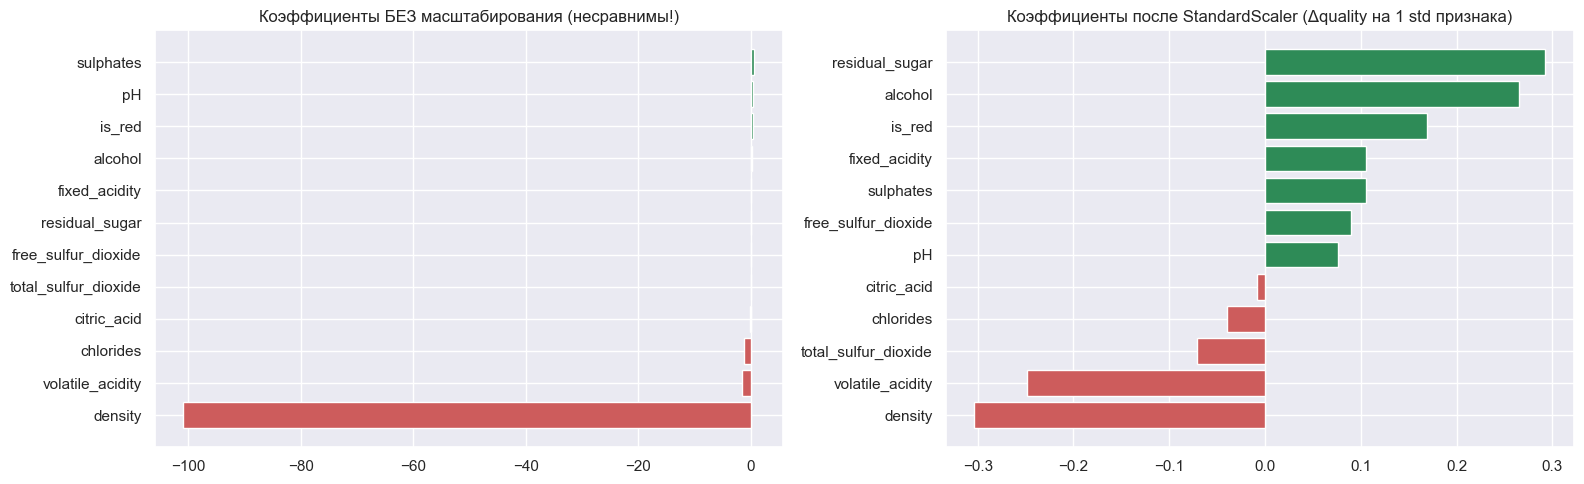

In [16]:
lr_raw.fit(X_train, y_train)
coefs = pd.DataFrame({
    "coef_raw": lr_raw.coef_,
    "feature_std": X_train.std().values,
    "coef_scaled": lr.named_steps["model"].coef_,
}, index=FEATURES).sort_values("coef_scaled", key=abs, ascending=False)

fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
c = coefs["coef_raw"].sort_values()
axs[0].barh(c.index, c.values, color=np.where(c.values > 0, "seagreen", "indianred"))
axs[0].set_title("Коэффициенты БЕЗ масштабирования (несравнимы!)")
c = coefs["coef_scaled"].sort_values()
axs[1].barh(c.index, c.values, color=np.where(c.values > 0, "seagreen", "indianred"))
axs[1].set_title("Коэффициенты после StandardScaler (Δquality на 1 std признака)")
plt.tight_layout()
coefs

**Анализ линейной регрессии:**
* RMSE ≈ 0.73 на test, **хуже порога 0.70**, хотя baseline она обходит заметно (≈ 0.87 → 0.73). Train RMSE почти такой же, как test: модель не переобучается, а **недообучается**. Зависимость quality от признаков нелинейна и неоднородна (разная для красных и белых), и одна гиперплоскость её не описывает.
* **Сырые коэффициенты вводят в заблуждение:** у `density` коэффициент огромный по модулю (десятки баллов на 1 г/см³), но std плотности ≈ 0.003. Реальный вклад определяется произведением коэффициента на std, что и показывает коэффициент после масштабирования.
* **По масштабированным коэффициентам** самые влиятельные признаки — `density` (−), `residual_sugar` (+), `alcohol` (+), `volatile_acidity` (−), `is_red` (+). Знаки у `alcohol` и `volatile_acidity` согласуются с EDA, а вот первые два места заслуживают отдельного разговора (см. ниже).
* **Ловушка мультиколлинеарности:** у `residual_sugar` положительный коэффициент, хотя в EDA его корреляция с качеством около нуля/отрицательная, а у `density` большой отрицательный коэффициент. Причина в том, что плотность почти линейно выражается через сахар и алкоголь (корреляции 0.55 и −0.69). Модель «раскладывает» общий эффект между коррелированными признаками, и при фиксированной плотности больший сахар означает больший алкоголь. Поэтому коэффициенты отдельных коррелированных признаков нельзя интерпретировать как самостоятельное влияние.

### 4.2 Random Forest Regressor

Случайный лес — ансамбль глубоких деревьев на бутстреп-выборках со случайным подмножеством признаков в каждом разбиении. Он улавливает нелинейности и взаимодействия (например, «тип вина × признак»), устойчив к выбросам и не требует масштабирования. Гиперпараметры подбираем на CV.

In [17]:
rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    {"max_features": [0.33, 0.5, 1.0], "min_samples_leaf": [1, 2, 5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1,
)
rf_search.fit(X_train, y_train)
print("best params:", rf_search.best_params_, " CV RMSE = %.4f" % -rf_search.best_score_)
pd.DataFrame(rf_search.cv_results_)[["param_max_features", "param_min_samples_leaf", "mean_test_score"]] \
    .assign(cv_rmse=lambda d: -d.mean_test_score).drop(columns="mean_test_score").sort_values("cv_rmse")

best params: {'max_features': 0.33, 'min_samples_leaf': 1}  CV RMSE = 0.6161


,param_max_features,param_min_samples_leaf,cv_rmse
0,0.33,1,0.616
3,0.50,1,0.619
4,0.50,2,0.623
1,0.33,2,0.624
6,1.00,1,0.625
7,1.00,2,0.629
5,0.50,5,0.642
8,1.00,5,0.644
2,0.33,5,0.646


In [18]:
rf = RandomForestRegressor(n_estimators=1000, random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_)
rf.fit(X_train, y_train)
evaluate("Random Forest", y_test, rf.predict(X_test))
print("Train RMSE: %.4f" % root_mean_squared_error(y_train, rf.predict(X_train)))

Random Forest             RMSE = 0.6118   MAE = 0.4378
Train RMSE: 0.2176


Лучшие параметры — неограниченная глубина и маленький лист, а также `max_features < 1`: декорреляция деревьев снижает дисперсию ансамбля. Train RMSE очень мал (лес почти запоминает обучающую выборку), но благодаря усреднению сотен деревьев на test ошибка всё равно значительно ниже, чем у линейной модели.

,MDI,permutation
alcohol,0.174,0.155
volatile_acidity,0.111,0.082
density,0.108,0.047
free_sulfur_dioxide,0.087,0.064
chlorides,0.085,0.036
total_sulfur_dioxide,0.078,0.037
residual_sugar,0.077,0.032
sulphates,0.073,0.041
citric_acid,0.072,0.036
pH,0.069,0.024


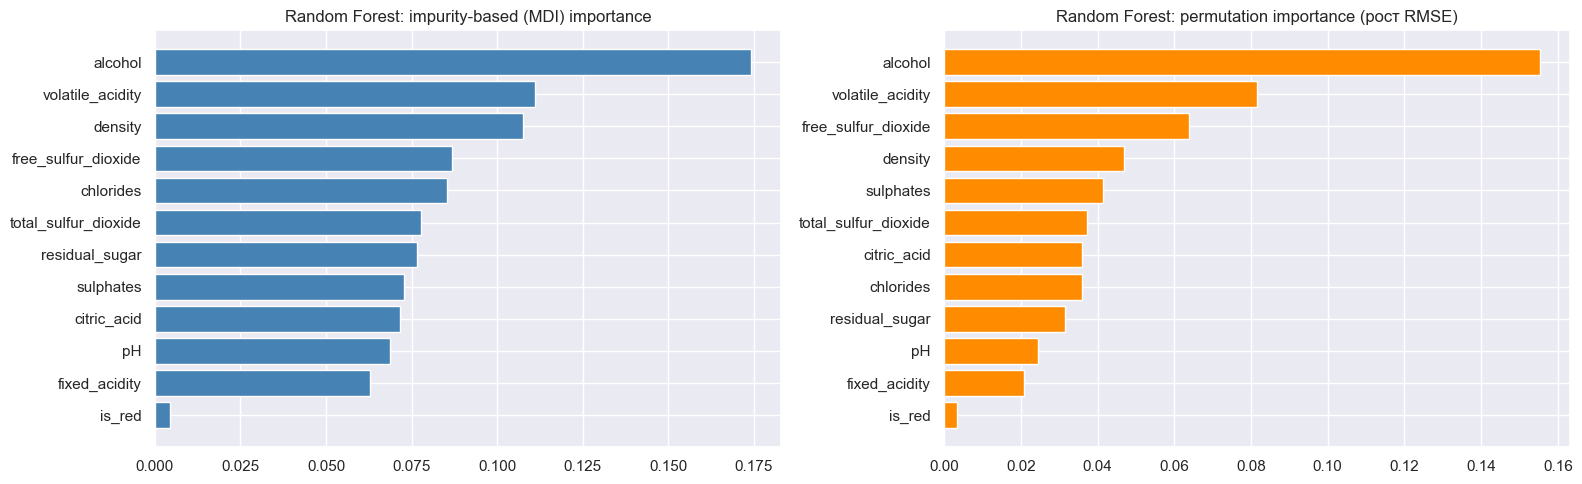

In [19]:
def plot_importances(imp_mdi, imp_perm, title):
    fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
    s = imp_mdi.sort_values()
    axs[0].barh(s.index, s.values, color="steelblue")
    axs[0].set_title(f"{title}: impurity-based (MDI) importance")
    s = imp_perm.sort_values()
    axs[1].barh(s.index, s.values, color="darkorange")
    axs[1].set_title(f"{title}: permutation importance (рост RMSE)")
    plt.tight_layout()

def perm_imp(model):
    # permutation importance считаем на test уже ПОСЛЕ того, как модель выбрана и зафиксирована:
    # это анализ, а не выбор модели, ответы теста ни на какие решения не влияют
    r = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
    return pd.Series(r.importances_mean, index=FEATURES)

rf_mdi = pd.Series(rf.feature_importances_, index=FEATURES)
rf_perm = perm_imp(rf)
plot_importances(rf_mdi, rf_perm, "Random Forest")
pd.DataFrame({"MDI": rf_mdi, "permutation": rf_perm}).sort_values("MDI", ascending=False)

**Важность признаков в Random Forest.** Смотрим два вида важности:
* **MDI** (`feature_importances_`) — суммарное снижение MSE в разбиениях по признаку. Считается по train и смещено в пользу признаков с большим числом уникальных значений.
* **Permutation importance** — насколько вырастает RMSE на отложенных данных, если перемешать признак. Это более честная мера «насколько модель на него опирается».

Самый важный признак в обоих случаях — **`alcohol`**, это совпадает с EDA (ρ ≈ 0.45) и с линейной моделью. Дальше идут **`volatile_acidity`**, **`free_sulfur_dioxide`**, `density`. При этом у `density` высокий MDI отчасти «заимствован» у алкоголя: признаки коррелированы, лес использует то один, то другой, и важность делится между ними. `is_red` имеет почти нулевую важность. Это не значит, что тип вина не важен: он почти однозначно восстанавливается по `total_sulfur_dioxide`, `chlorides` и др., поэтому информация о типе уже есть в других признаках.

Отличия от линейной модели: у RF заметно важнее `free_sulfur_dioxide` (у линейной модели коэффициент небольшой) — связь нелинейна: слишком мало SO₂ — вино окисляется, слишком много — неприятный запах, и линейная модель такой «колокол» уловить не может. `residual_sugar` у RF средней важности, а у линейной модели большой коэффициент — опять артефакт коллинеарности с `density`.

### 4.3 Gradient Boosting Regressor

Градиентный бустинг строит неглубокие деревья последовательно, и каждое следующее исправляет ошибки (антиградиент функции потерь) текущего ансамбля. Параметры по умолчанию (100 деревьев глубины 3, lr=0.1) для этой задачи слишком «слабые», поэтому подбираем их рандомизированным поиском по CV на train.

In [20]:
gb_default = GradientBoostingRegressor(random_state=RANDOM_STATE)
print("CV RMSE GB (default params): %.4f ± %.4f" % cv_rmse(gb_default))

gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    {
        "n_estimators": [300, 500, 800, 1200],
        "learning_rate": [0.01, 0.02, 0.05, 0.1],
        "max_depth": [3, 4, 5, 6, 8],
        "min_samples_leaf": [1, 3, 5, 10],
        "subsample": [0.6, 0.8, 1.0],
        "max_features": [0.5, 0.7, 1.0],
    },
    n_iter=40, cv=cv, scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1,
)
gb_search.fit(X_train, y_train)
print("best params:", gb_search.best_params_)
print("CV RMSE (tuned) = %.4f" % -gb_search.best_score_)

CV RMSE GB (default params): 0.6823 ± 0.0188


best params: {'subsample': 1.0, 'n_estimators': 1200, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 8, 'learning_rate': 0.1}
CV RMSE (tuned) = 0.6272


In [21]:
gb = gb_search.best_estimator_
evaluate("Gradient Boosting", y_test, gb.predict(X_test))
print("Train RMSE: %.4f" % root_mean_squared_error(y_train, gb.predict(X_train)))

Gradient Boosting         RMSE = 0.6258   MAE = 0.4125
Train RMSE: 0.0043


,MDI,permutation
alcohol,0.174,1.144e-01
density,0.130,7.943e-02
volatile_acidity,0.127,9.197e-02
free_sulfur_dioxide,0.089,7.807e-02
residual_sugar,0.080,4.091e-02
total_sulfur_dioxide,0.074,5.681e-02
sulphates,0.071,4.775e-02
chlorides,0.068,2.808e-02
pH,0.066,3.486e-02
citric_acid,0.060,2.528e-02


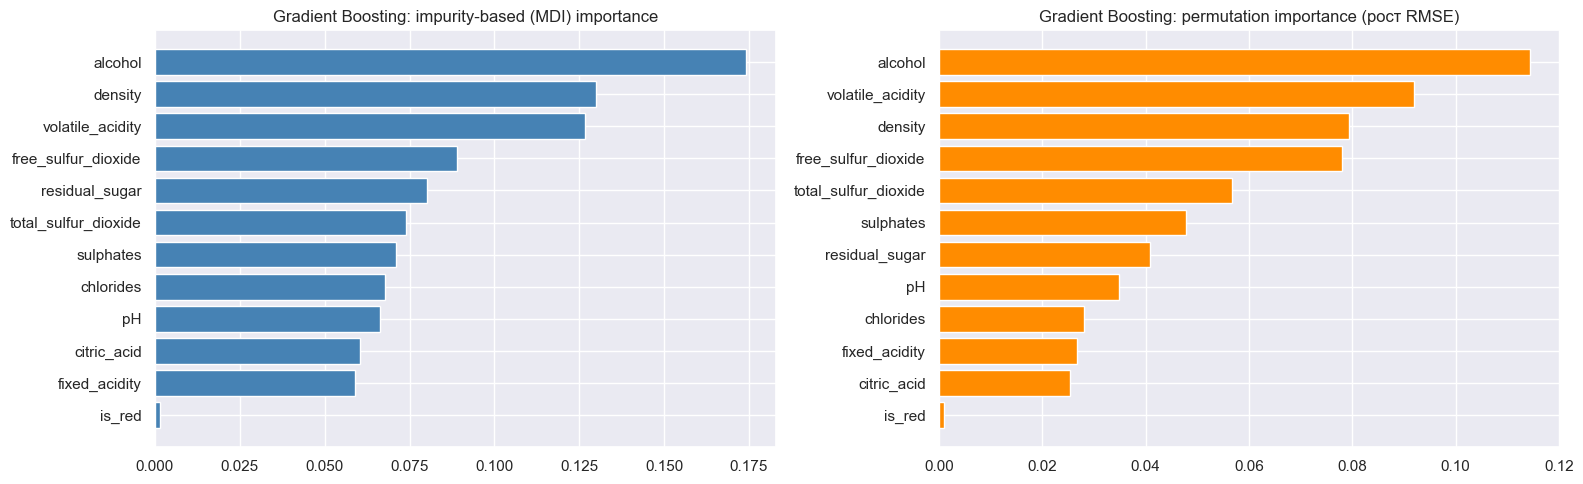

In [22]:
gb_mdi = pd.Series(gb.feature_importances_, index=FEATURES)
gb_perm = perm_imp(gb)
plot_importances(gb_mdi, gb_perm, "Gradient Boosting")
pd.DataFrame({"MDI": gb_mdi, "permutation": gb_perm}).sort_values("MDI", ascending=False)

### 4.4 (Дополнительно) Extra Trees

Extremely Randomized Trees — родственник случайного леса: пороги разбиения выбираются случайно, по умолчанию без бутстрепа. Это ещё сильнее декоррелирует деревья и снижает дисперсию. На шумных табличных данных средней величины такая модель часто чуть точнее RF. Параметры подбираем так же, на CV.

In [23]:
et_search = GridSearchCV(
    ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    {"max_features": [0.5, 0.7, 1.0], "min_samples_leaf": [1, 2, 3]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1,
)
et_search.fit(X_train, y_train)
print("best params:", et_search.best_params_, " CV RMSE = %.4f" % -et_search.best_score_)

et = ExtraTreesRegressor(n_estimators=1000, random_state=RANDOM_STATE, n_jobs=-1, **et_search.best_params_)
et.fit(X_train, y_train)
evaluate("Extra Trees", y_test, et.predict(X_test))

best params: {'max_features': 0.5, 'min_samples_leaf': 1}  CV RMSE = 0.6059


Extra Trees               RMSE = 0.5996   MAE = 0.3907


## 5. Честное сравнение моделей

In [24]:
cv_scores = {
    "Baseline (mean)": cv_rmse(DummyRegressor())[0],
    "Linear Regression": cv_rmse(lr)[0],
    "Random Forest": -rf_search.best_score_,
    "Gradient Boosting": -gb_search.best_score_,
    "Extra Trees": -et_search.best_score_,
}
summary = pd.DataFrame(results).T
summary.insert(0, "CV RMSE (train)", pd.Series(cv_scores))
summary["RMSE/MAE"] = summary["RMSE"] / summary["MAE"]
summary["vs baseline, %"] = (1 - summary["RMSE"] / summary.loc["Baseline (mean)", "RMSE"]) * 100
summary["RMSE < 0.70"] = summary["RMSE"] < 0.70
summary.round(4)

,CV RMSE (train),RMSE,MAE,RMSE/MAE,"vs baseline, %",RMSE < 0.70
Baseline (mean),0.873,0.873,0.685,1.274,0.000,False
Linear Regression,0.735,0.732,0.567,1.291,16.173,False
Random Forest,0.616,0.612,0.438,1.398,29.931,True
Gradient Boosting,0.627,0.626,0.412,1.517,28.326,True
Extra Trees,0.606,0.600,0.391,1.535,31.327,True


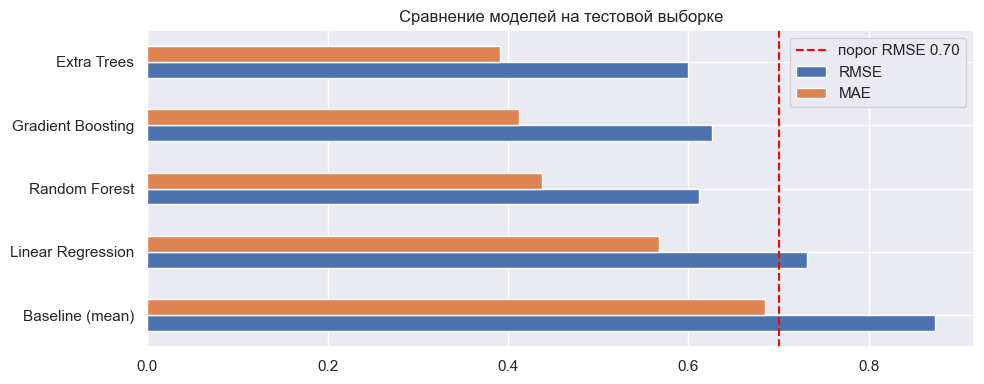

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
s = summary[["RMSE", "MAE"]]
s.plot(kind="barh", ax=ax)
ax.axvline(0.70, color="red", ls="--", label="порог RMSE 0.70")
ax.legend()
ax.set_title("Сравнение моделей на тестовой выборке")
plt.tight_layout()

**Выводы по сравнению:**
* **Baseline превзошли все модели.** Значит, признаки действительно несут информацию о качестве. Порог RMSE < 0.70 проходят только ансамбли деревьев. Линейная регрессия улучшает baseline всего на ~16% и порог не проходит.
* Оценки CV на train и на test хорошо согласуются, и порядок моделей одинаковый. Значит, выбор модели по CV надёжен, и тест мы не «подгоняли».
* **Почему линейная модель хуже:** у неё высокое смещение. Зависимость quality от признаков нелинейна: у алкоголя эффект сильнее в верхнем диапазоне, у диоксида серы оптимум в середине. Кроме того, она неоднородна: для красных и белых вин важны разные признаки (`sulphates`, `citric_acid`), то есть есть взаимодействия с типом, которых в линейной модели нет. Ещё её смещают выбросы в скошенных признаках.
* **Почему ансамбли деревьев лучше:** деревья сами находят пороги и взаимодействия, нечувствительны к масштабу и монотонным преобразованиям, устойчивы к выбросам.
* **RF / Extra Trees против Gradient Boosting:** здесь методы, основанные на усреднении глубоких деревьев (снижение *дисперсии*), оказались не хуже или лучше бустинга (снижение *смещения*). Данные очень шумные (субъективная экспертная оценка), а в датасете много дубликатов и почти-дубликатов. Глубокие деревья леса почти «запоминают» локальные окрестности объектов, и для близких или повторяющихся вин это хорошо срабатывает. Бустинг с параметрами по умолчанию недообучается (CV ≈ 0.68). После подбора, с глубокими деревьями и малым lr, он приближается к лесу и по сути тоже начинает «запоминать». Extra Trees ещё сильнее декоррелирует деревья, поэтому дисперсия ансамбля у него наименьшая.
* Отношение RMSE/MAE у ансамблей деревьев больше (≈ 1.4–1.55), чем у линейной модели (≈ 1.29). Ансамбли делают много очень точных прогнозов (на «знакомых» винах ошибка близка к нулю), но крупные промахи на редких оценках остаются. Распределение их ошибок более «тяжелохвостое», что и раздувает RMSE относительно MAE.

### 5.1 Проверка влияния дубликатов

Около 18% строк — дубликаты, поэтому часть тестовых объектов имеет точные копии в train. Проверим качество отдельно на тестовых объектах, **у которых нет копии в train**. Это не выбор модели, а проверка надёжности уже полученной оценки.

In [26]:
train_keys = set(map(tuple, X_train.values))
in_train = np.array([tuple(r) in train_keys for r in X_test.values])
print(f"Тестовых объектов с точной копией в train: {in_train.sum()} из {len(in_train)} ({in_train.mean():.1%})")

models = {"Baseline (mean)": None, "Linear Regression": lr, "Random Forest": rf, "Gradient Boosting": gb, "Extra Trees": et}
rows = {}
for name, m in models.items():
    pred = np.full(len(X_test), const_mean) if m is None else m.predict(X_test)
    rows[name] = {
        "RMSE (все)": root_mean_squared_error(y_test, pred),
        "RMSE (без копий в train)": root_mean_squared_error(y_test[~in_train], pred[~in_train]),
        "RMSE (есть копия в train)": root_mean_squared_error(y_test[in_train], pred[in_train]),
    }
pd.DataFrame(rows).T.round(4)

Тестовых объектов с точной копией в train: 345 из 1300 (26.5%)


,RMSE (все),RMSE (без копий в train),RMSE (есть копия в train)
Baseline (mean),0.873,0.890,0.824
Linear Regression,0.732,0.742,0.703
Random Forest,0.612,0.702,0.217
Gradient Boosting,0.626,0.730,0.005
Extra Trees,0.600,0.700,0.000


Это важное наблюдение, и его стоит сформулировать честно:
* На объектах-копиях ансамбли деревьев почти безошибочны (RMSE ≈ 0–0.2): глубокие деревья просто «вспоминают» ответ. Линейная модель на них ошибается так же, как на остальных.
* На «новых» винах, у которых нет копии в train, RMSE ансамблей ≈ 0.70–0.73, то есть ровно на границе порога. Значит, часть итогового выигрыша (0.60 против ≈ 0.70) объясняется дубликатами.
* При этом **и на новых винах деревья заметно лучше линейной модели** (0.70 против 0.74) и baseline (0.89). Их превосходство не сводится к запоминанию.
* Скрытая тестовая выборка строится из того же датасета, поэтому дубликаты, скорее всего, будут и в ней. Итоговая модель (раздел 8) обучается на всех 6497 объектах и «знает» все повторяющиеся вина. Ожидаемое качество на скрытом тесте ≈ 0.60–0.62, примерно как на нашем тесте.

## 6. Feature importance: сравнение моделей

Ранги признаков (1 = самый важный):


,|LR coef| (scaled),RF (MDI),GB (MDI),ET (MDI),RF (perm),GB (perm),|Spearman| EDA
alcohol,3,1,1,1,1,1,1
volatile_acidity,4,2,3,2,2,2,4
free_sulfur_dioxide,8,4,4,3,3,4,8
density,1,3,2,4,4,3,2
sulphates,7,8,7,7,5,6,11
total_sulfur_dioxide,10,6,6,5,6,5,9
citric_acid,12,9,10,9,7,11,6
chlorides,11,5,8,8,8,9,3
residual_sugar,2,7,5,6,9,7,12
pH,9,10,9,10,10,8,10


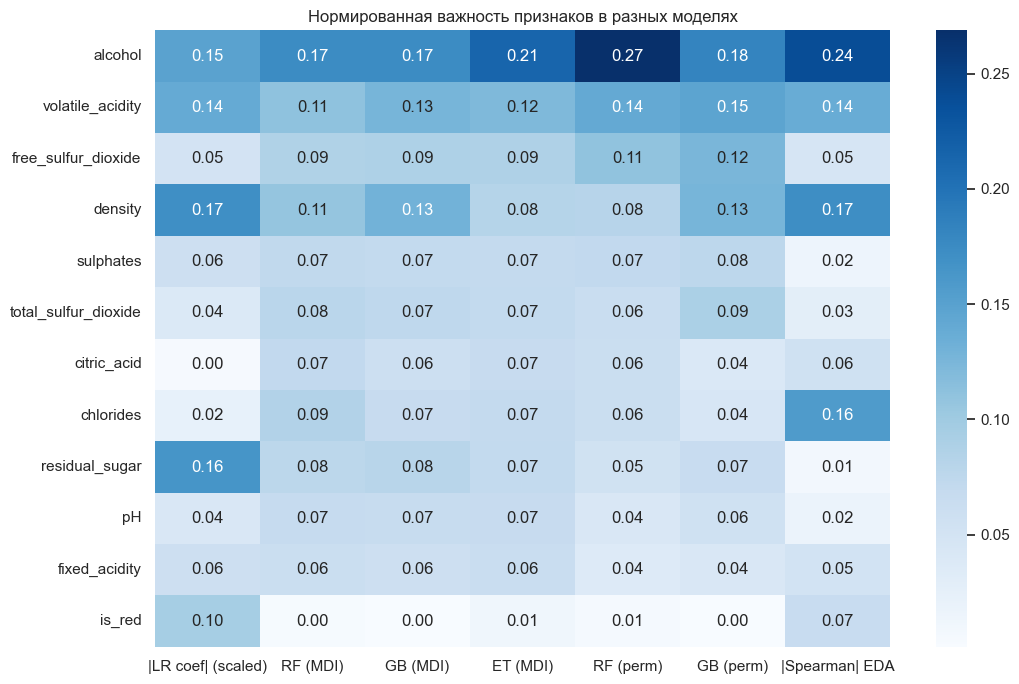

In [27]:
et_mdi = pd.Series(et.feature_importances_, index=FEATURES)
lr_abs = coefs["coef_scaled"].abs()

imp = pd.DataFrame({
    "|LR coef| (scaled)": lr_abs / lr_abs.sum(),
    "RF (MDI)": rf_mdi,
    "GB (MDI)": gb_mdi,
    "ET (MDI)": et_mdi,
    "RF (perm)": rf_perm / rf_perm.clip(lower=0).sum(),
    "GB (perm)": gb_perm / gb_perm.clip(lower=0).sum(),
    "|Spearman| EDA": corr_all.abs() / corr_all.abs().sum(),
}).loc[FEATURES]
imp = imp.sort_values("RF (perm)", ascending=False)

plt.figure(figsize=(11, 7))
sns.heatmap(imp, annot=True, fmt=".2f", cmap="Blues")
plt.title("Нормированная важность признаков в разных моделях")
plt.tight_layout()

print("Ранги признаков (1 = самый важный):")
imp.rank(ascending=False).astype(int)

**Сравнение важности признаков:**
1. **`alcohol` — главный признак во всех моделях и в EDA.** Это самый устойчивый вывод работы.
2. **`volatile_acidity`** входит в топ-3 у всех моделей: согласуется с EDA и физическим смыслом (уксусная кислота — дефект).
3. **`free_sulfur_dioxide`** у деревьев (RF, GB) заметно важнее, чем у линейной модели и в корреляциях. Это пример **нелинейной** зависимости (оптимум в середине диапазона), которую корреляция и линейная модель недооценивают.
4. **`density` и `residual_sugar`** у линейной модели получают завышенные веса из-за мультиколлинеарности. У деревьев важность плотности умеренная и делится с `alcohol`, корреляция которых ≈ −0.69.
5. **RF и GB** дают очень похожие рейтинги: в топ-4 у обоих одни и те же признаки (`alcohol`, `volatile_acidity`, `density`, `free_sulfur_dioxide`), отличается только порядок внутри. У бустинга `density` поднимается на 2–3 место. Бустинг последовательно доучивает остатки, и, когда основной сигнал алкоголя уже учтён, следующие деревья используют плотность как дополнительный, более «гладкий» прокси того же эффекта (алкоголь + сахар). У RF из-за `max_features = 0.33` в каждом разбиении доступна лишь треть признаков, и важность распределяется равномернее.
6. `is_red` у всех деревьев на последнем месте: тип вина почти однозначно восстанавливается по другим признакам. У линейной модели он на 5-м месте, потому что без взаимодействий ей нужен отдельный сдвиг для красных вин.

**Можно ли по feature importance утверждать, что изменение признака является *причиной* изменения качества?** **Нет.**
* Feature importance показывает, насколько **модель** использует признак для **прогноза**, то есть отражает статистическую ассоциацию в данных, а не причинно-следственную связь.
* Данные **наблюдательные**: никто не менял алкоголь у одного и того же вина при прочих равных. Высокий алкоголь и высокая оценка могут иметь общую причину (**конфаундер**): спелость винограда, сорт, год, технология и опыт винодела. Эти факторы одновременно влияют и на крепость, и на вкус. Добавив спирт в слабое вино, мы не получим отличное вино.
* При коррелированных признаках важность **делится или переносится** между ними (`density` ↔ `alcohol`, `free` ↔ `total SO₂`). Признак может быть «важным», лишь потому что он прокси для другого, и наоборот.
* Значения важности зависят от модели и способа подсчёта (MDI смещён к непрерывным признакам), что мы и видим в таблице выше.
* Для причинных выводов нужны контролируемые эксперименты или методы causal inference. Feature importance подходит для понимания модели и отбора признаков, но не для выводов «что изменить в вине».

## 7. Анализ ошибок лучшей модели

Лучшую модель выбираем **по CV на train** (по тесту не выбираем): это модель с минимальным CV RMSE.

In [28]:
candidates = {"Random Forest": rf, "Gradient Boosting": gb, "Extra Trees": et}
best_name = min(candidates, key=lambda n: cv_scores[n])
best = candidates[best_name]
print("Лучшая модель по CV:", best_name, " CV RMSE = %.4f" % cv_scores[best_name],
      " test RMSE = %.4f" % results[best_name]["RMSE"])

err = pd.DataFrame({"y_true": y_test, "y_pred": best.predict(X_test)}, index=y_test.index)
err["error"] = err["y_pred"] - err["y_true"]
err["abs_error"] = err["error"].abs()
err["is_red"] = X_test["is_red"]

Лучшая модель по CV: Extra Trees  CV RMSE = 0.6059  test RMSE = 0.5996


count    1300.000
mean        0.024
std         0.599
min        -3.400
25%        -0.219
50%         0.000
75%         0.304
max         2.869
Name: error, dtype: float64
Доля |ошибка| < 0.5 (округление даёт верный балл): 69.5%
Доля |ошибка| > 1: 9.6%


,n,MAE,RMSE,mean_bias
y_true,,,,
3,5,2.179,2.216,2.179
4,45,1.127,1.269,1.127
5,427,0.362,0.516,0.349
6,568,0.250,0.368,-0.055
7,216,0.482,0.656,-0.477
8,37,1.073,1.372,-1.073
9,2,2.864,2.913,-2.864


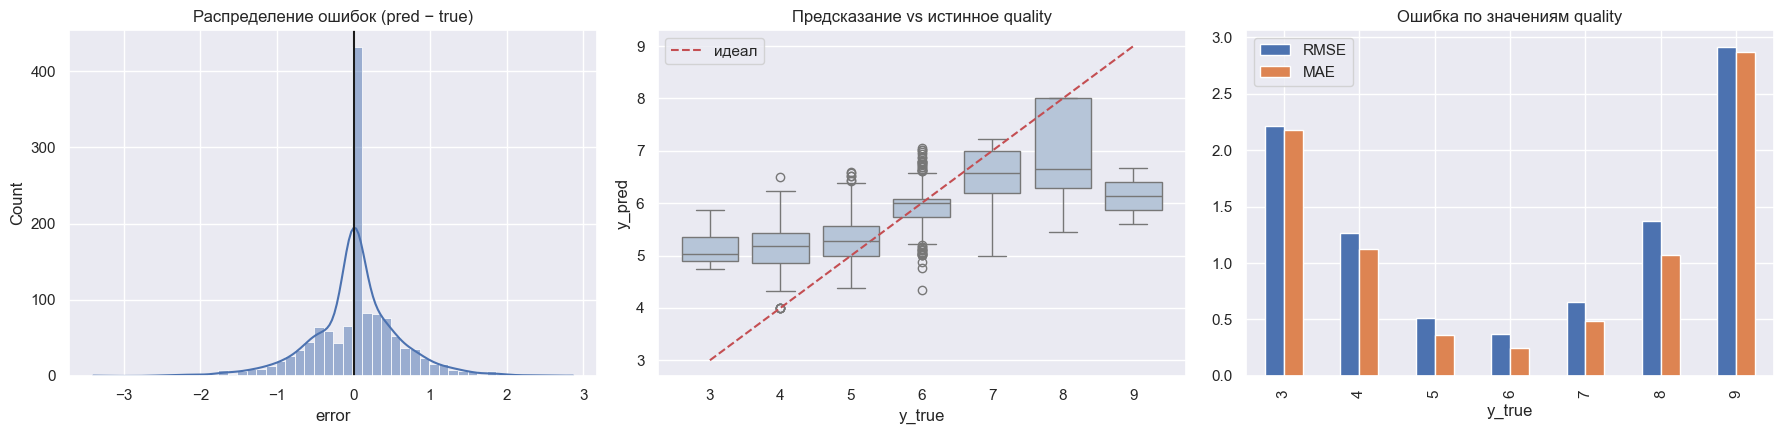

In [29]:
fig, axs = plt.subplots(figsize=(18, 4.5), ncols=3)
sns.histplot(err["error"], bins=50, ax=axs[0], kde=True)
axs[0].axvline(0, color="k")
axs[0].set_title("Распределение ошибок (pred − true)")

sns.boxplot(data=err, x="y_true", y="y_pred", ax=axs[1], color="lightsteelblue")
lo, hi = err.y_true.min(), err.y_true.max()
axs[1].plot(range(0, hi - lo + 1), range(lo, hi + 1), "r--", label="идеал")
axs[1].legend()
axs[1].set_title("Предсказание vs истинное quality")

by_q = err.groupby("y_true").agg(n=("error", "size"), MAE=("abs_error", "mean"),
                                  RMSE=("error", lambda e: np.sqrt((e ** 2).mean())),
                                  mean_bias=("error", "mean"))
by_q[["RMSE", "MAE"]].plot(kind="bar", ax=axs[2])
axs[2].set_title("Ошибка по значениям quality")
plt.tight_layout()

print(err["error"].describe().round(3))
print("Доля |ошибка| < 0.5 (округление даёт верный балл): %.1f%%" % (100 * (err.abs_error < 0.5).mean()))
print("Доля |ошибка| > 1: %.1f%%" % (100 * (err.abs_error > 1).mean()))
by_q.round(3)

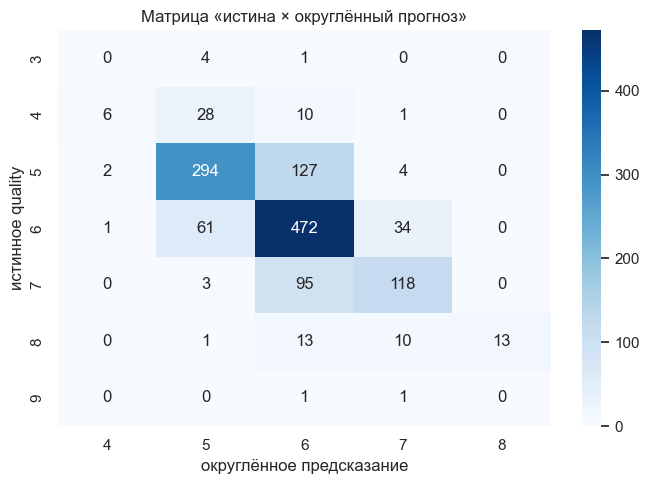

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))
cm = pd.crosstab(err["y_true"], err["y_pred"].round().astype(int).clip(3, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_xlabel("округлённое предсказание")
ax.set_ylabel("истинное quality")
ax.set_title("Матрица «истина × округлённый прогноз»")
plt.tight_layout()

In [31]:
worst = err.sort_values("abs_error", ascending=False).head(10)
worst_full = worst.drop(columns="is_red").join(X_test)
cols_show = ["y_true", "y_pred", "error", "is_red", "alcohol", "volatile_acidity",
             "free_sulfur_dioxide", "residual_sugar", "sulphates", "chlorides"]
print("Медианы признаков по оценкам (train) для сравнения:")
display(pd.concat([X_train, y_train], axis=1).groupby(TARGET)[cols_show[4:]].median())
worst_full[cols_show]

Медианы признаков по оценкам (train) для сравнения:


,alcohol,volatile_acidity,free_sulfur_dioxide,residual_sugar,sulphates,chlorides
quality,,,,,,
3,9.95,0.330,18.0,3.5,0.510,0.057
4,10.00,0.380,15.0,2.2,0.490,0.052
5,9.60,0.330,27.0,3.0,0.500,0.053
6,10.45,0.270,30.0,3.0,0.510,0.046
7,11.40,0.270,31.0,2.8,0.520,0.039
8,11.95,0.275,34.0,4.2,0.465,0.036
9,12.70,0.360,31.0,2.2,0.420,0.021


,y_true,y_pred,error,is_red,alcohol,volatile_acidity,free_sulfur_dioxide,residual_sugar,sulphates,chlorides
2373,9,5.600,-3.400,0,10.4,0.27,28.0,10.6,0.46,0.035
4686,3,5.869,2.869,0,10.1,0.20,38.0,9.5,0.44,0.041
5088,8,5.453,-2.547,0,11.4,0.28,7.0,7.4,0.47,0.041
5335,4,6.504,2.504,0,12.7,0.32,18.0,8.0,0.79,0.026
459,3,5.355,2.355,1,9.0,0.58,10.0,2.2,0.57,0.074
2426,9,6.673,-2.327,0,12.5,0.24,27.0,2.0,0.48,0.031
1619,8,5.700,-2.300,0,12.8,0.66,29.0,1.2,0.39,0.029
1616,8,5.700,-2.300,0,12.8,0.66,29.0,1.2,0.39,0.029
5369,4,6.228,2.228,0,12.0,0.27,15.0,2.4,0.65,0.014
1403,8,5.900,-2.100,1,10.0,0.33,3.0,1.7,1.10,0.061


**Анализ ошибок:**
* **Распределение ошибок** симметрично (среднее ≈ 0.02, медиана 0) и имеет острый пик: большинство прогнозов очень близки к истине. Но хвосты длиннее нормальных (min −3.4, max +2.9), отсюда отношение RMSE/MAE ≈ 1.53. Округлённый прогноз совпадает с истинной оценкой в ~70% случаев, ошибка больше 1 балла — у ~10% объектов.
* **Модель работает неодинаково для разных quality.** Для частых оценок 5 и 6 RMSE ≈ 0.37–0.52, а для 4 и 8 уже ≈ 1.3–1.4, для 3 и 9 больше 2. Систематический сдвиг (`mean_bias`): низкие оценки **переоцениваются**, высокие **недооцениваются**. Это классическая **регрессия к среднему**.
* **Почему хуже на редких значениях quality:**
  1. Мало примеров: оценок 3 и 9 в train единицы, модели почти не на чем учиться.
  2. Регрессия с MSE минимизирует *среднюю* ошибку, и ей выгоднее хорошо предсказывать массовые 5–6. Каждый лист дерева усредняет соседние объекты, а среди соседей редкого объекта почти всегда больше «средних» вин, поэтому прогноз стягивается к центру.
  3. Вина с экстремальными оценками часто экстремальны и по признакам. В таких областях признакового пространства данных мало, деревья не экстраполируют за пределы диапазона train.
* **Конкретные сильные ошибки** (таблица выше):
  * **Белые вина с оценками 3–4, которым модель ставит 5.9–6.5** (объекты 4686, 5335, 5369). По измеренным признакам они выглядят как хорошие вина: у 5335 и 5369 алкоголь 12–12.7% (медиана для оценки 8 — 11.95%), низкие хлориды, у 4686 очень низкая `volatile_acidity` (0.20). Признаков дефекта в данных нет. Скорее всего, недостаток вина не отражён в 11 физико-химических измерениях (посторонний запах, пробковый дефект, окисление), или оценка эксперта субъективна.
  * **Белое вино с оценкой 9, предсказание 5.6** (объект 2373). Алкоголь 10.4% (типично для оценки 5–6), сахар 10.6. В train всего 3 вина с оценкой 9, модели не на чем выучить такой профиль, и прогноз стягивается к среднему.
  * **Вина с оценкой 8 и «плохими» признаками.** Объекты 1616 и 1619 (дубликаты друг друга) при высоком алкоголе 12.8% имеют очень высокую `volatile_acidity` 0.66 (типично для плохих вин), и модель ставит 5.7. У объекта 5088 крайне мало свободного SO₂ (7 мг/л), у красного 1403 — низкий алкоголь (10%) и очень высокие сульфаты (1.1). Признаки «спорят» между собой, и в таких редких сочетаниях модель усредняет соседей с оценками 5–6.
  * Ещё один источник ошибок — **шум разметки**: оценка — медиана мнений минимум трёх экспертов, и неопределённость около ±1 балла заложена в саму целевую переменную. У очень похожих по признакам вин оценки могут отличаться на 1–2 балла. Это нижняя граница достижимой ошибки, ни одна модель её не преодолеет.
* **Что можно улучшить:** взвешивать редкие классы, попробовать ordinal-регрессию или классификацию с последующим ожидаемым значением, добавить признаки-взаимодействия (`alcohol × is_red`, отношение `free/total SO₂`). Но основная часть ошибки — неустранимый шум субъективных оценок.

## 8. Итоговая модель для скрытой тестовой выборки

Выбранная по CV модель переобучается **на всех данных** (train + test) с теми же гиперпараметрами: оценка качества уже получена, а больше данных — лучше обобщение. Модель сохраняется в `best_model.joblib`. Функция `predict_quality` принимает таблицу с исходными колонками UCI (с пробелами или подчёркиваниями в названиях) и признаком типа вина: `is_red` (0/1) или `type`/`color` (`"red"` / `"white"`).

In [32]:
import joblib
from sklearn.base import clone

final_model = clone(best).fit(X, y)
joblib.dump({"model": final_model, "features": FEATURES}, "best_model.joblib", compress=3)
print("Сохранено:", best_name, final_model)

def predict_quality(data: pd.DataFrame, path="best_model.joblib") -> np.ndarray:
    bundle = joblib.load(path)
    d = data.rename(columns=lambda c: c.strip().replace(" ", "_"))
    if "is_red" not in d.columns:
        type_col = next(c for c in ["type", "color", "colour", "wine_type"] if c in d.columns)
        d["is_red"] = (d[type_col].astype(str).str.lower() == "red").astype(int)
    return bundle["model"].predict(d[bundle["features"]])

# проверка: функция работает на «сыром» формате UCI
raw_red = pd.read_csv("data/winequality-red.csv", sep=";").drop(columns="quality").assign(type="red")
print(predict_quality(raw_red.head()))

Сохранено: Extra Trees ExtraTreesRegressor(max_features=0.5, n_estimators=1000, n_jobs=-1,
                    random_state=42)


[5. 5. 5. 6. 5.]


## 9. Общие выводы

1. **Данные:** 6497 вин (красные + белые), 11 физико-химических признаков, пропусков нет, ~18% дубликатов. Целевая переменная сильно несбалансирована (77% — оценки 5–6) и шумная (субъективная экспертная оценка).
2. **Baseline** (среднее по train) даёт RMSE ≈ 0.87, MAE ≈ 0.68. Это нижняя планка полезности модели.
3. **Линейная регрессия** обходит baseline, но с RMSE ≈ 0.73 не проходит порог: зависимости нелинейны и различаются для красных и белых вин. Для интерпретации коэффициентов признаки нужно стандартизировать, и даже после этого мультиколлинеарность (`density`–`alcohol`–`residual_sugar`) искажает веса.
4. **Ансамбли деревьев** проходят порог RMSE < 0.70 и улучшают baseline на 28–31%: Random Forest — RMSE 0.612 / MAE 0.438, Gradient Boosting — 0.626 / 0.412, Extra Trees — **0.600 / 0.391** (лучшая и по CV, и на test). Модель выбрана по CV, без использования теста. Часть выигрыша объясняется дубликатами в данных (раздел 5.1): на «новых» винах RMSE ≈ 0.70.
5. **Главные признаки:** `alcohol` (во всех моделях №1), `volatile_acidity`, `free_sulfur_dioxide`, далее `density`, `sulphates`. Это согласуется с EDA, но feature importance не означает причинности.
6. **Ошибки** сосредоточены на редких крайних оценках (3–4 и 8–9): модель стягивает их к среднему. Основная причина — дефицит примеров и неустранимый шум разметки.